# 02 · Data preparation

**Owner:** Charlotte

In [7]:
import sys
import os

sys.path.insert(0, os.path.abspath(".."))

from src.data import load_train
from src.preprocessing import add_engineered_features, build_preprocessor

import matplotlib.pyplot as plt

FIG_PATH = os.path.join("..", "results", "figures", "eda")
os.makedirs(FIG_PATH, exist_ok=True)

In [8]:
X_train, y_train = load_train()

preprocessor = build_preprocessor(use_engineered=False)
X_transformed = preprocessor.fit_transform(X_train)
print("Shape without engineered features:", X_transformed.shape)

X_eng = add_engineered_features(X_train)
preprocessor_eng = build_preprocessor(use_engineered=True)
X_transformed_eng = preprocessor_eng.fit_transform(X_eng)
print("Shape with engineered features:", X_transformed_eng.shape)

Shape without engineered features: (1684, 35)
Shape with engineered features: (1684, 37)


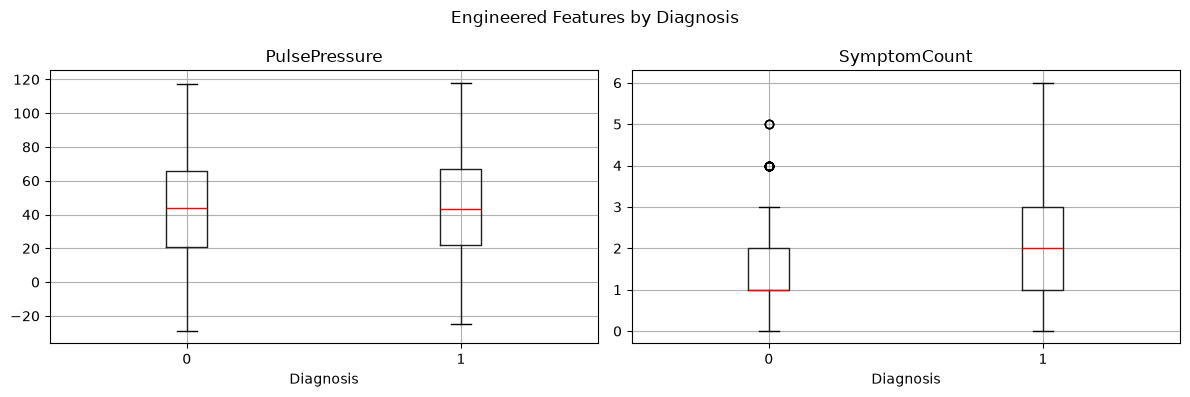

In [10]:
X_eng["Diagnosis"] = y_train.values

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
X_eng.boxplot(column="PulsePressure", by="Diagnosis", ax=axes[0], medianprops={"color": "red"})
X_eng.boxplot(column="SymptomCount", by="Diagnosis", ax=axes[1], medianprops={"color": "red"})
plt.suptitle("Engineered Features by Diagnosis")
plt.tight_layout()
plt.savefig(os.path.join(FIG_PATH, "engineered_features.png"), dpi=150)
plt.show()

## Data preperation justifications:

*Most is used in perprocessing.py*

### Scaling — StandardScaler
Support Vector Machine (SVM) and Multilayer Perceptron (MLP) are both sensitive to feature scale. SVM maximises a margin 
in feature space — large-scale features would dominate the distance 
calculation. MLP uses gradient descent — unscaled features cause 
slow or unstable convergence. StandardScaler (zero mean, unit variance) 
is applied to all 15 continuous features. The scaler is fitted inside 
each CV fold via Pipeline to prevent data leakage.

### Ethnicity — OneHotEncoder
Ethnicity is a nominal categorical variable with no natural ordering 
between categories. Assigning integer codes (0, 1, 2...) would imply 
a false ordinal relationship. OneHotEncoder creates a binary column 
per category, avoiding this. handle_unknown="ignore" ensures unseen 
categories during test time do not cause errors.

### Passthrough Features — Binary & EducationLevel

**Binary features (15 columns):**
All binary features (e.g. Gender, Smoking, Tremor, Rigidity...) are 
already encoded as 0/1 integers. No transformation is needed — they 
are on a comparable scale by definition and passed through as-is.

**EducationLevel (ordinal):**
EducationLevel has a natural ordering: None < High School < 
Bachelor's < Higher. The integer codes (0–3) already reflect this 
progression, so no additional encoding is needed. It is passed 
through as-is alongside the binary features.

### Imputation — None required
check_quality() in the data understanding notebook confirmed zero 
missing values across all features. No imputation step is included 
in the pipeline.

### Outliers — Retained
Z-score analysis (threshold > 3) in the data understanding notebook 
identified no outliers across any continuous feature. This is expected 
given the synthetic data generation process — all values fall within 
documented ranges by design. No observations are removed.

### Engineered Features

**PulsePressure = SystolicBP − DiastolicBP**
PulsePressure is **dropped** from the feature set. The box plots show 
near-identical distributions for PD and Non-PD patients, with overlapping 
medians (~45 mmHg) and interquartile ranges. It adds no meaningful 
discriminative information beyond what SystolicBP and DiastolicBP 
already capture individually.

**SymptomCount = sum of 7 symptom flags**
SymptomCount is **retained**. Box plots show a clearly higher median 
symptom count in PD patients (median = 2) compared to Non-PD patients 
(median = 1). Furthermore, the distribution of Non-PD patients shows 
a floor effect — values are bounded at 0 and right-skewed toward low 
counts, while PD patients show a wider and higher distribution. This 
meaningful separation between classes justifies its inclusion as an 
engineered feature. The two outliers observed in the Non-PD group 
(counts of 4 and 5) are retained, as they fall within the possible 
range of the feature by definition.
